# VINH — NLP / SKILL EXTRACTION + CHROMADB + RAG AGENT + API (VIETJOBS)

**Google Colab · Dữ liệu gốc VietJobs 48.092 tin tuyển dụng**

> **Phạm vi :** (1) tiền xử lý JD, (2) trích xuất kỹ năng, chuẩn hóa Skill IDs, (3) embedding & ChromaDB, (4) RAG Agent hỏi đáp có dẫn nguồn, (5) API gọi từ Supervisor và kiểm thử.

**Phân biệt train/inference:** chỉ mô hình **TF-IDF + One-vs-Rest Logistic Regression** được huấn luyện có giám sát trên nhãn kỹ năng VietJobs. Mô hình embedding và LLM (nếu bật) là **pretrained, không fine-tune**. Nhãn `technical_skills` là nhãn tham chiếu từ dataset, **chưa được gán/kiểm duyệt thủ công**; F1 chỉ đánh giá trên nhãn này.

**Nguồn gốc:** https://huggingface.co/datasets/dinhieufam/VietJobs (kiểm tra điều kiện phân phối dữ liệu trước khi đăng công khai). Chạy **Runtime → Run all** trên Google Colab. CPU đủ cho phần train/chroma nhỏ; chọn GPU T4 nếu bật LLM local.

**Sau khi chạy:** `outputs/vietjobs_skill_extractor.joblib`, `outputs/skill_id_mapping.csv`, `outputs/metrics.json`, `outputs/chroma_db/`, `src/vinh_agents.py`, `src/api.py`.

## 0. Cài môi trường

In [1]:
%pip install -q "python-dateutil==2.9.0.post0"

In [2]:
%pip install -q "sentence-transformers>=3.4,<6" "chromadb>=1.0,<2" "fastapi>=0.110,<1" "uvicorn>=0.30,<1" "httpx>=0.27,<1" requests joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
t

## 1. Cấu hình và cấu trúc thư mục

- `ONLY_IT=True`: chỉ xét ngành CNTT dựa theo `category`/`job_title`.
- `MAX_TRAIN_ROWS=None`: dùng **toàn bộ JD đã lọc có nhãn** (không ép thành 48.092 JD IT).
- `RAG_LIMIT=1000`: chỉ mục 1.000 JD IT đầu tiên sau lấy mẫu ngẫu nhiên để chạy thử; có thể tăng khi đủ RAM/thời gian.
- `ENABLE_LLM=False`: chạy được ngay trên CPU; bật `True` sau khi bật GPU nếu muốn LLM sinh câu trả lời thay vì chỉ trả JD liên quan.

In [3]:
import os, re, ast, html, sys, json, hashlib, unicodedata, shutil, zipfile
from collections import Counter
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, hamming_loss

SEED = 42
ONLY_IT = True
MAX_TRAIN_ROWS = None   # None = toàn bộ JD có nhãn hợp lệ
MIN_TRAIN_POS = 12
MAX_LABELS = 35
MIN_TEXT_CHARS = 60
RAG_LIMIT = 1000
MAX_CHUNKS_PER_JD = 3
RESET_CHROMA_ON_REBUILD = True
ENABLE_LLM = False       # True: tải model Qwen 0.5B, nên chọn GPU T4 trước
AUTO_DOWNLOAD_ZIP = False

PROJECT = Path('/content/vinh_vietjobs') if Path('/content').exists() else Path.cwd() / 'vinh_vietjobs'
DATA_DIR = PROJECT / 'data'
OUT = PROJECT / 'outputs'
SRC = PROJECT / 'src'
for p in (DATA_DIR, OUT, SRC): p.mkdir(parents=True, exist_ok=True)
(SRC / '__init__.py').touch(exist_ok=True)
sys.path.insert(0, str(PROJECT))
print('Python:', sys.version.split()[0], '| workspace:', PROJECT)

Python: 3.13.16 | workspace: /content/vinh_vietjobs


## 2. Tải VietJobs.csv



In [4]:
from requests import Session
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Nếu upload file qua thanh Files của Colab, nó thường nằm ở /content/.
for file_name in ('VietJobs.csv.gz', 'VietJobs.csv'):
    colab_upload = Path('/content') / file_name
    target_local = DATA_DIR / file_name
    if colab_upload.exists() and not target_local.exists():
        shutil.copy2(colab_upload, target_local)
possible = [DATA_DIR/'VietJobs.csv.gz', DATA_DIR/'VietJobs.csv']
csv_path = next((p for p in possible if p.exists()), None)
if csv_path is None:
    url = 'https://huggingface.co/datasets/dinhieufam/VietJobs/resolve/main/VietJobs.csv'
    s = Session()
    s.mount('https://', HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1,
                                                      status_forcelist=[429, 500, 502, 503, 504])))
    target = DATA_DIR / 'VietJobs.csv'
    try:
        with s.get(url, stream=True, timeout=(20, 120)) as response:
            response.raise_for_status()
            with target.open('wb') as f:
                for block in response.iter_content(chunk_size=1024*1024):
                    if block: f.write(block)
        if target.stat().st_size < 200000:
            raise ValueError('Tệp tải về quá nhỏ; có thể không phải dữ liệu CSV.')
        csv_path = target
    except Exception as exc:
        target.unlink(missing_ok=True)
        print('Không tải được CSV tự động:', repr(exc))
        print('Hãy chạy cell upload dự phòng ở dưới.')
print('Dataset path:', csv_path)

Dataset path: /content/vinh_vietjobs/data/VietJobs.csv


In [7]:
if csv_path is None:
    from google.colab import files
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(('.csv','.csv.gz'))]
    if not candidates:
        raise ValueError('Hãy upload VietJobs.csv hoặc VietJobs.csv.gz')
    csv_path = DATA_DIR / Path(candidates[0]).name
    csv_path.write_bytes(uploaded[candidates[0]])

raw = pd.read_csv(csv_path, low_memory=False, encoding='utf-8-sig', compression='infer')
required_cols = {'job_title','description','requirements_text','technical_skills','category'}
assert required_cols.issubset(raw.columns), f'Thiếu các cột: {required_cols-set(raw.columns)}'
print('Số JD gốc:', len(raw))
print('Danh sách cột:', raw.columns.tolist())
display(raw[['job_title','category','technical_skills']].head(100))

Số JD gốc: 48092
Danh sách cột: ['job_title', 'location', 'country', 'qualifications', 'technical_skills', 'soft_skills', 'languages_required', 'experience_required', 'salary', 'contract_type', 'working_hours', 'benefits', 'description', 'requirements_text', 'category', 'salary_min', 'salary_max', 'salary_avg']


,job_title,category,technical_skills
0,Nhân Viên Vận Hành Hệ Thống Xử Lý Nước Thải,nông_nghiệp_năng_lượng_môi_trường,NaN
1,Nhân Viên Vận Hành Hệ Thống Xử Lí Nước Thải,nông_nghiệp_năng_lượng_môi_trường,"['Vận hành hệ thống xử lý nước thải', 'Phân tí..."
2,Nhân Viên Phát Triển Thị Trường,nông_nghiệp_năng_lượng_môi_trường,NaN
3,Nhân Viên Bảo Trì Hệ Thống Xử Lý Nước,nông_nghiệp_năng_lượng_môi_trường,NaN
4,Chuyên Gia Đánh Giá ISO 22000–HACCP–VIETGAP,nông_nghiệp_năng_lượng_môi_trường,"['HACCP', 'ISO 22000', 'VietGAP', 'GLOBAL GAP']"
...,...,...,...
95,Kỹ Sư Môi Trường (Thiết Kế Công Nghệ),nông_nghiệp_năng_lượng_môi_trường,"['Phần mềm Autocad', 'Biết Revit là 1 lợi thế']"
96,Chuyên Viên Thiết Kế,nông_nghiệp_năng_lượng_môi_trường,"['Autocad', 'Revit']"
97,Nhân Viên An Toàn Lao Động,nông_nghiệp_năng_lượng_môi_trường,['Chuyên môn về ATLĐ']
98,Trưởng Phòng Kỹ Thuật,nông_nghiệp_năng_lượng_môi_trường,"['Kỹ thuật phân bón', 'Kỹ thuật BVTV']"


## 3. Làm sạch JD, chuẩn hóa tên kỹ năng và Skill IDs cố định

- **Input mô hình:** `job_title`, `description`, `requirements_text`.
- **Nhãn train:** `technical_skills` (chỉ để tạo Y, **không ghép vào input X** để tránh data leakage).
- Skill IDs được gán ổn định theo toàn bộ taxonomy `SK001…`, không thay đổi theo thứ tự kỹ năng top-35 của lần train.
- Regex hiện hỗ trợ một bộ kỹ năng phổ biến, chưa bao phủ toàn bộ ngành; cần nhóm Vũ/Việt/Vương thống nhất taxonomy khi tích hợp.

In [8]:
SKILL_PATTERNS = {
    'Python':       [r'\bpython\b'],
    'Java':         [r'\bjava\b(?!\s*script)'],
    'JavaScript':   [r'\bjavascript\b', r'\bjava\s*script\b', r'\bjs\b'],
    'TypeScript':   [r'\btypescript\b'],
    'C#':           [r'(?<!\w)c\s*#(?!\w)', r'\bcsharp\b'],
    'C++':          [r'(?<!\w)c\s*\+\+(?!\w)'],
    'PHP':          [r'\bphp\b'],
    'Go':           [r'\bgolang\b', r'\bgo language\b'],
    'Kotlin':       [r'\bkotlin\b'],
    'Swift':        [r'\bswift\b'],
    'SQL':          [r'\bsql\b', r'\bsql server\b'],
    'MySQL':        [r'\bmysql\b'],
    'PostgreSQL':   [r'\bpostgres(?:ql)?\b'],
    'MongoDB':      [r'\bmongodb\b'],
    'Redis':        [r'\bredis\b'],
    'React':        [r'\breact(?:js|\.js)?\b'],
    'Angular':      [r'\bangular\b'],
    'Vue':          [r'\bvue(?:js|\.js)?\b'],
    'Node.js':      [r'\bnode(?:js|\.js)?\b'],
    'Spring Boot':  [r'\bspring\s*boot\b'],
    '.NET':         [r'(?<!\w)\.net\b', r'\basp\.?net\b'],
    'Django':       [r'\bdjango\b'],
    'FastAPI':      [r'\bfastapi\b'],
    'Laravel':      [r'\blaravel\b'],
    'HTML/CSS':     [r'\bhtml\b',r'\bcss\b'],
    'Docker':       [r'\bdocker\b'],
    'Kubernetes':   [r'\bkubernetes\b', r'\bk8s\b'],
    'Linux':        [r'\blinux\b'],
    'AWS':          [r'\baws\b', r'\bamazon web services\b'],
    'Azure':        [r'\bazure\b'],
    'GCP':          [r'\bgcp\b',r'\bgoogle cloud\b'],
    'Git':          [r'\bgit\b',r'\bgithub\b',r'\bgitlab\b'],
    'CI/CD':        [r'\bci\s*/\s*cd\b',r'\bcontinuous integration\b'],
    'TensorFlow':   [r'\btensorflow\b'],
    'PyTorch':      [r'\bpytorch\b'],
    'Machine Learning': [r'\bmachine learning\b', r'hoc may',r'\bml\b'],
    'NLP':          [r'\bnlp\b', r'xu ly ngon ngu tu nhien'],
    'Data Analysis':[r'\bdata analy(?:sis|tics)\b',r'phan tich du lieu'],
    'Power BI':     [r'\bpower\s*bi\b'],
    'Excel':        [r'\bexcel\b'],
    'REST API':     [r'\brest(?:ful)?\s*api\b',r'\bapi rest\b'],
    'Microservices': [r'\bmicroservices?\b', r'kien truc vi dich vu'],
    'Kafka':        [r'\bkafka\b'],
    'Spark':        [r'\bapache spark\b',r'\bspark\b'],
    'Selenium':     [r'\bselenium\b'],
    'Figma':        [r'\bfigma\b'],
    'Jira':         [r'\bjira\b'],
    'Scrum':        [r'\bscrum\b'],
}
COMPILED_SKILLS = {k: [re.compile(p, re.I) for p in patterns]
                   for k, patterns in SKILL_PATTERNS.items()}

def clean_text(value):
    if value is None or pd.isna(value):
        return ''
    value = html.unescape(str(value))
    value = re.sub(r'<[^>]+>', ' ', value)
    return re.sub(r'\s+', ' ', value).strip()

def simplify(text):
    text = str(text or '').lower()
    text = unicodedata.normalize('NFD', text)
    text = ''.join(ch for ch in text if unicodedata.category(ch) != 'Mn')
    return text.replace('đ', 'd')

def parse_skill_list(value):
    if isinstance(value, list):
        return [str(x).strip() for x in value if str(x).strip()]
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    s = str(value).strip()
    if s.lower() in ('', 'nan', 'none', 'null', '[]'):
        return []
    if s.startswith('['):
        try:
            parsed = ast.literal_eval(s)
            if isinstance(parsed, (list, tuple)):
                return [str(x).strip() for x in parsed if str(x).strip()]
        except (ValueError, SyntaxError):
            pass
    return [part.strip(' []\"\'') for part in re.split(r'\s*[;,\n]\s*', s) if part.strip(' []\"\'')]

def normalize_skills(value):
    skills = parse_skill_list(value)
    # matching is done on labels only, never on the model input
    search_text = ' || '.join(skills)
    normalized = simplify(search_text)
    result=[]
    for name, patterns in COMPILED_SKILLS.items():
        if any(p.search(normalized) for p in patterns):
            result.append(name)
    return result



# Bảng mã có phiên bản: các ID không phụ thuộc số lần train / top-35.
TAXONOMY_VERSION = 'vietjobs_skills_v1'
ALL_SKILL_NAMES = sorted(SKILL_PATTERNS)
ID_BY_SKILL = {name: f'SK{i+1:03d}' for i, name in enumerate(ALL_SKILL_NAMES)}
print('Tổng kỹ năng taxonomy:', len(ALL_SKILL_NAMES))
print('Ví dụ:', normalize_skills("['Python', 'Docker', 'SQL']"))

Tổng kỹ năng taxonomy: 48
Ví dụ: ['Python', 'SQL', 'Docker']


## 4. Lọc JD IT, khử trùng lặp, tạo tập train và tập RAG

Tập dùng cho RAG gồm JD IT có mô tả hợp lệ **kể cả khi thiếu `technical_skills`**. Tập train chỉ gồm JD có ít nhất một nhãn hợp lệ. Khử trùng theo văn bản chuẩn hóa **trước khi chia train/test**.

Nhóm ngành trong nguồn:


,jobs
category,
kinh_doanh_bán_hàng_chăm_sóc_khách_hàng,8276
sản_xuất_lao_động_phổ_thông_cơ_khí,6407
marketing_truyền_thông_quảng_cáo_nội_dung,5950
tài_chính_kế_toán_ngân_hàng_bảo_hiểm,5530
du_lịch_nhà_hàng_khách_sạn_dịch_vụ,4243
thiết_kế_nghệ_thuật_giải_trí_truyền_hình_báo_chí,3465
nhân_sự_hành_chính_pháp_chế_tư_vấn,3276
xây_dựng_kiến_trúc_bất_động_sản,2811
công_nghệ_thông_tin_kỹ_thuật_số,1906


Tổng nguồn: 48092 | JD IT hợp lệ cho RAG: 2976 | JD IT có nhãn để train: 1116


,skill_name,n_JD
0,SQL,308
1,Python,275
2,Java,253
3,Git,185
4,Excel,182
5,JavaScript,180
6,AWS,121
7,MySQL,119
8,Docker,119
9,React,107


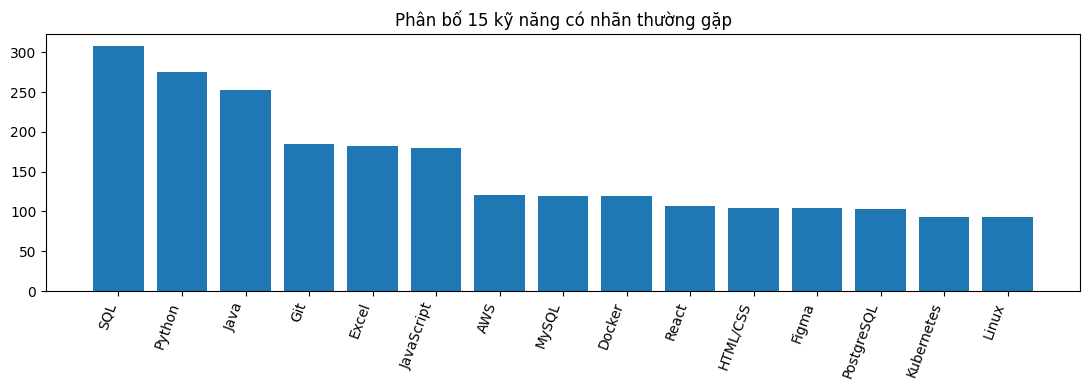

In [9]:
def category_is_it(value):
    v = simplify(value).replace(' ', '_')
    return bool(re.search(r'cong_nghe_thong_tin|cong_nghe|phan_mem|technology|information_technology', v))

def title_is_it(value):
    v = simplify(value)
    return bool(re.search(r'\b(?:developer|devops|data engineer|data scientist|software|backend|back.?end|front.?end|full.?stack|qa engineer|it support|machine learning|ai engineer|tester|sysadmin|system administrator|database administrator)\b|\blap trinh\b|\bky su phan mem\b|\bcong nghe thong tin\b|\bkiem thu phan mem\b', v))

df_all = raw.copy()
for c in ['job_title','description','requirements_text','technical_skills','category','location']:
    if c not in df_all.columns: df_all[c] = ''
    df_all[c] = df_all[c].fillna('')
print('Nhóm ngành trong nguồn:')
display(df_all['category'].value_counts().head(15).to_frame('jobs'))
if ONLY_IT:
    keep = df_all['category'].apply(category_is_it) | df_all['job_title'].apply(title_is_it)
    df_all = df_all.loc[keep].copy()
for c in ['job_title','description','requirements_text','location','category']:
    df_all[c] = df_all[c].map(clean_text)
df_all['text'] = (df_all['job_title'] + '. ' + df_all['description'] + ' ' + df_all['requirements_text']).str.replace(r'\s+', ' ', regex=True).str.strip()
df_all = df_all.loc[df_all['text'].str.len() >= MIN_TEXT_CHARS].copy()
df_all['text_key'] = df_all['text'].map(lambda x: re.sub(r'\s+', ' ', simplify(x)).strip())
df_all = df_all.drop_duplicates('text_key').reset_index(drop=True)
df_all['job_id'] = df_all['text_key'].map(lambda x: hashlib.sha256(x.encode('utf-8')).hexdigest()[:16])
df_all['labels_all'] = df_all['technical_skills'].map(normalize_skills)
rag_df = df_all.copy()
trainable = df_all[df_all['labels_all'].map(bool)].copy()
if MAX_TRAIN_ROWS is not None and len(trainable)>MAX_TRAIN_ROWS:
    trainable = trainable.sample(n=MAX_TRAIN_ROWS,random_state=SEED).reset_index(drop=True)
print('Tổng nguồn:',len(raw),'| JD IT hợp lệ cho RAG:',len(rag_df),'| JD IT có nhãn để train:',len(trainable))
if len(trainable) < 100:
    raise ValueError('Quá ít JD IT có nhãn. Xem dữ liệu category/technical_skills và cân nhắc ONLY_IT=False.')
counts=Counter(skill for labels in trainable['labels_all'] for skill in labels)
display(pd.DataFrame(counts.most_common(25), columns=['skill_name','n_JD']))
plt.figure(figsize=(11, 4))
labels, values = zip(*counts.most_common(15))
plt.bar(labels, values); plt.xticks(rotation=70, ha='right'); plt.title('Phân bố 15 kỹ năng có nhãn thường gặp'); plt.tight_layout(); plt.show()

## 5. Chia Train/Validation/Test 80/10/10

Vì dữ liệu đa nhãn, split ngẫu nhiên ở đây là baseline; có thể chuyển sang iterative stratification sau. Bộ nhãn được chọn **chỉ dựa trên tập train**; tiêu chí ngưỡng chọn **chỉ dựa trên validation**; test đánh giá đúng một lần.

In [10]:
train_df, tmp_df = train_test_split(trainable, test_size=0.2, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.5, random_state=SEED)
train_counts = Counter(k for labels in train_df['labels_all'] for k in labels)
selected = [name for name, freq in train_counts.most_common() if freq >= MIN_TRAIN_POS][:MAX_LABELS]
selected = sorted(selected)
if len(selected) < 2: raise RuntimeError('Quá ít nhãn. Giảm MIN_TRAIN_POS hoặc ONLY_IT=False.')
mlb = MultiLabelBinarizer(classes=selected)
mlb.fit([[]])
def transform_labels(frame):
    return mlb.transform([[x for x in labels if x in selected] for labels in frame['labels_all']]).astype(np.int8)
Y_train, Y_val, Y_test = map(transform_labels, (train_df,val_df,test_df))
X_train, X_val, X_test = (part['text'].tolist() for part in (train_df,val_df,test_df))
print('Train/Val/Test:',len(train_df),len(val_df),len(test_df))
print('Số nhãn:',len(selected),'| kỹ năng:',selected)
print('Tổng nhãn dương trong Train:',Y_train.sum(axis=0).tolist())
assert train_df['job_id'].is_unique and set(train_df['job_id']).isdisjoint(test_df['job_id'])

Train/Val/Test: 892 112 112
Số nhãn: 35 | kỹ năng: ['.NET', 'AWS', 'Angular', 'Azure', 'C#', 'C++', 'CI/CD', 'Docker', 'Excel', 'Figma', 'GCP', 'Git', 'HTML/CSS', 'Java', 'JavaScript', 'Jira', 'Kafka', 'Kubernetes', 'Linux', 'Machine Learning', 'Microservices', 'MongoDB', 'MySQL', 'Node.js', 'PHP', 'PostgreSQL', 'Python', 'REST API', 'React', 'Redis', 'SQL', 'Scrum', 'Spring Boot', 'TypeScript', 'Vue']
Tổng nhãn dương trong Train: [41, 103, 40, 52, 70, 46, 55, 98, 140, 81, 39, 150, 77, 208, 138, 60, 38, 79, 74, 25, 36, 70, 99, 52, 46, 88, 226, 50, 87, 39, 246, 26, 47, 39, 26]


## 6. TRAIN: TF-IDF + Logistic Regression đa nhãn

Có thể chạy trên Colab CPU. Đây là mô hình train thật trên dữ liệu tải về, không sử dụng dữ liệu minh họa giả lập. Độ chính xác phụ thuộc dữ liệu có nhãn và lựa chọn tham số.

In [11]:
vectorizer = TfidfVectorizer(lowercase=True, strip_accents='unicode',
    ngram_range=(1,2), min_df=2, max_df=0.98,
    max_features=60000, sublinear_tf=True, dtype=np.float32)
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
Xte = vectorizer.transform(X_test)
classifier = OneVsRestClassifier(
    LogisticRegression(solver='liblinear', max_iter=1000,
                       class_weight='balanced', random_state=SEED), n_jobs=1)
classifier.fit(Xtr, Y_train)
print('TRAIN DONE: Xtr', Xtr.shape,'| Ytr',Y_train.shape)

TRAIN DONE: Xtr (892, 20382) | Ytr (892, 35)


## 7. VALIDATION: chọn threshold; TEST: báo cáo Precision / Recall / F1

F1 này phản ánh việc khớp **nhãn `technical_skills` đã chuẩn hóa**, không phải độ chính xác đã được con người thẩm định. Không dùng Test để điều chỉnh threshold.

{
  "dataset": "dinhieufam/VietJobs",
  "label_source": "technical_skills normalized / weak labels",
  "taxonomy_version": "vietjobs_skills_v1",
  "n_raw": 48092,
  "n_rag_it_valid": 2976,
  "n_train": 892,
  "n_val": 112,
  "n_test": 112,
  "n_classes": 35,
  "threshold": 0.45,
  "validation_micro_f1": 0.6606217616580311,
  "test_micro_precision": 0.5496688741721855,
  "test_micro_recall": 0.7854889589905363,
  "test_micro_f1": 0.6467532467532467,
  "test_macro_f1": 0.5964370203360052,
  "test_hamming_loss": 0.06938775510204082
}


,precision,recall,f1-score,support
.NET,0.800000,0.444444,0.571429,9.0
AWS,0.400000,1.000000,0.571429,8.0
Angular,0.333333,0.666667,0.444444,3.0
Azure,0.400000,1.000000,0.571429,4.0
C#,0.555556,0.714286,0.625000,7.0
C++,1.000000,0.625000,0.769231,8.0
CI/CD,0.636364,0.875000,0.736842,8.0
Docker,0.550000,0.785714,0.647059,14.0
Excel,0.857143,0.818182,0.837209,22.0
Figma,0.588235,0.909091,0.714286,11.0


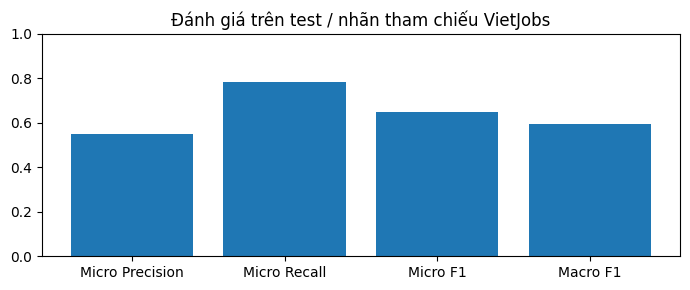

In [12]:
val_prob = classifier.predict_proba(Xva)
trial_thresholds = np.round(np.arange(0.15, 0.76, 0.05), 2)
score_grid = [(float(t), f1_score(Y_val, (val_prob>=t).astype(int), average='micro', zero_division=0))
              for t in trial_thresholds]
threshold, val_micro_f1 = max(score_grid, key=lambda x: x[1])
test_prob = classifier.predict_proba(Xte)
test_pred = (test_prob >= threshold).astype(int)
metrics = {
  'dataset':'dinhieufam/VietJobs', 'label_source':'technical_skills normalized / weak labels',
  'taxonomy_version':TAXONOMY_VERSION, 'n_raw':int(len(raw)),
  'n_rag_it_valid':int(len(rag_df)), 'n_train':int(len(train_df)),
  'n_val':int(len(val_df)), 'n_test':int(len(test_df)),
  'n_classes':int(len(selected)), 'threshold':float(threshold),
  'validation_micro_f1':float(val_micro_f1),
  'test_micro_precision':float(precision_score(Y_test,test_pred,average='micro',zero_division=0)),
  'test_micro_recall':float(recall_score(Y_test,test_pred,average='micro',zero_division=0)),
  'test_micro_f1':float(f1_score(Y_test,test_pred,average='micro',zero_division=0)),
  'test_macro_f1':float(f1_score(Y_test,test_pred,average='macro',zero_division=0)),
  'test_hamming_loss':float(hamming_loss(Y_test,test_pred))
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))
per_skill_report = pd.DataFrame(classification_report(
    Y_test,test_pred,target_names=selected,zero_division=0,output_dict=True)).T
per_skill_report.to_csv(OUT/'per_skill_report.csv',encoding='utf-8-sig')
display(per_skill_report.head(20))
fig,ax=plt.subplots(figsize=(7,3))
ax.bar(['Micro Precision','Micro Recall','Micro F1','Macro F1'],
       [metrics['test_micro_precision'],metrics['test_micro_recall'],metrics['test_micro_f1'],metrics['test_macro_f1']])
ax.set_ylim(0,1); ax.set_title('Đánh giá trên test / nhãn tham chiếu VietJobs'); plt.tight_layout(); plt.show()

## 8. Lưu mô hình và Skill IDs phiên bản hóa

`joblib` là định dạng pickle: **chỉ load file do bạn hoặc nhóm tin tưởng tạo ra**. Mapping cố định toàn taxonomy; cột `trained` giúp Vương/Việt biết lớp kỹ năng nào đang được mô hình dự đoán.

In [13]:
skill_mapping = pd.DataFrame({
    'skill_id':[ID_BY_SKILL[name] for name in ALL_SKILL_NAMES],
    'skill_name':ALL_SKILL_NAMES,
    'trained':[name in selected for name in ALL_SKILL_NAMES],
    'taxonomy_version':TAXONOMY_VERSION
})
skill_mapping.to_csv(OUT/'skill_id_mapping.csv',index=False,encoding='utf-8-sig')
artifact = {'vectorizer':vectorizer,'classifier':classifier,
            'classes':selected,'threshold':threshold,
            'skill_mapping':{name:ID_BY_SKILL[name] for name in selected},
            'taxonomy_version':TAXONOMY_VERSION,
            'input_fields':['job_title','description','requirements_text'],
            'label_field':'technical_skills','dataset':'dinhieufam/VietJobs'}
joblib.dump(artifact,OUT/'vietjobs_skill_extractor.joblib',compress=3)
(OUT/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
print('Saved:', sorted(f.name for f in OUT.iterdir() if f.is_file()))

Saved: ['metrics.json', 'per_skill_report.csv', 'skill_id_mapping.csv', 'vietjobs_skill_extractor.joblib']


## 9. Sinh modules để gọi được từ Supervisor / chạy API

Cell bên dưới tự tạo `src/vinh_agents.py` và `src/api.py` **ngay trên Colab**. Trong bản ZIP đính kèm, hai tệp `.py` này cũng được cung cấp để chạy tại VS Code hoặc triển khai sau.

In [14]:
(SRC/'vinh_agents.py').write_text(r'''
"""NLP skill extractor + semantic retrieval + optional local-LLM RAG.

Self-contained inference module for use by Supervisor / FastAPI.
All model downloads happen only when the corresponding function is first used.
"""
import os
from functools import lru_cache
from pathlib import Path
import joblib
import numpy as np

DEFAULT_EMBEDDING = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
DEFAULT_LLM = "Qwen/Qwen2.5-0.5B-Instruct"


@lru_cache(maxsize=2)
def get_embedder(model_name=DEFAULT_EMBEDDING):
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer(model_name)


@lru_cache(maxsize=1)
def get_llm(model_name=DEFAULT_LLM):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device).eval()
    return tokenizer, model, device


class VinhAgent:
    """Loaded model + retrieval module; paths can point to a persisted Drive folder."""

    def __init__(self, model_dir=None, chroma_dir=None):
        root = Path(model_dir or os.environ.get("VINH_MODEL_DIR", "outputs"))
        model_path = root / "vietjobs_skill_extractor.joblib"
        if not model_path.exists():
            raise FileNotFoundError(f"Missing trained classifier: {model_path}")
        # ONLY load artifacts that you created/trust: joblib is Python pickle.
        self.artifact = joblib.load(model_path)
        self.vectorizer = self.artifact["vectorizer"]
        self.classifier = self.artifact["classifier"]
        self.classes = list(self.artifact["classes"])
        self.mapping = self.artifact["skill_mapping"]
        self.threshold = float(self.artifact["threshold"])
        self.chroma_dir = Path(chroma_dir or os.environ.get("VINH_CHROMA_DIR", str(root / "chroma_db")))
        self._collection = None

    def extract_skills(self, text, top_k=12, threshold=None):
        if not isinstance(text, str) or not text.strip():
            return []
        probs = self.classifier.predict_proba(self.vectorizer.transform([text]))[0]
        cutoff = self.threshold if threshold is None else float(threshold)
        order = np.argsort(-probs)[:max(1, min(int(top_k), len(self.classes)))]
        return [
            {"skill_id": self.mapping[self.classes[i]],
             "skill_name": self.classes[i],
             "confidence": round(float(probs[i]), 4)}
            for i in order if probs[i] >= cutoff
        ]

    def _get_collection(self):
        if self._collection is None:
            import chromadb
            client = chromadb.PersistentClient(path=str(self.chroma_dir))
            try:
                self._collection = client.get_collection(name="vietjobs_jds")
            except Exception as exc:
                raise RuntimeError("ChromaDB chưa có index. Hãy chạy cell tạo embeddings trước.") from exc
        return self._collection

    def search_jobs(self, query, top_k=5, category=None):
        if not isinstance(query, str) or not query.strip():
            return []
        collection = self._get_collection()
        count = collection.count()
        if count < 1:
            return []
        embedder = get_embedder()
        q_vec = embedder.encode([query], normalize_embeddings=True, convert_to_numpy=True).tolist()
        args = {"query_embeddings": q_vec,
                "n_results": min(count, max(int(top_k) * 5, int(top_k))),
                "include": ["documents", "metadatas", "distances"]}
        if category:
            args["where"] = {"category": str(category)}
        results = collection.query(**args)
        seen = set()
        rows = []
        for chunk_id, doc, meta, distance in zip(
            results["ids"][0], results["documents"][0],
            results["metadatas"][0], results["distances"][0]
        ):
            job_id = str(meta.get("job_id") or chunk_id)
            if job_id in seen:
                continue
            seen.add(job_id)
            rows.append({
                "job_id": job_id,
                "chunk_id": chunk_id,
                "title": str(meta.get("title", "")),
                "category": str(meta.get("category", "")),
                "location": str(meta.get("location", "")),
                "snippet": str(doc)[:800],
                "distance": round(float(distance), 4),
            })
            if len(rows) >= int(top_k):
                break
        return rows

    def ask_rag(self, question, top_k=5, use_llm=False):
        hits = self.search_jobs(question, top_k=top_k)
        if not hits:
            return {"question": question, "answer": "Không tìm thấy JD phù hợp trong chỉ mục.",
                    "mode": "no_results", "sources": []}
        sources = [{"ref": f"[{i}]", **hit} for i, hit in enumerate(hits, 1)]
        evidence = "\n\n".join(
            f"[{i}] {h['title']} | {h['location']}\n{h['snippet'][:650]}"
            for i, h in enumerate(hits, 1)
        )
        if not use_llm:
            answer = "Các JD liên quan được tìm thấy:\n" + "\n".join(
                f"[{i}] {h['title']} ({h['location'] or 'không rõ địa điểm'}). "
                f"Thông tin: {h['snippet'][:180]}..." for i, h in enumerate(hits, 1)
            )
            return {"question": question, "answer": answer,
                    "mode": "retrieval_only", "sources": sources}
        import torch
        tokenizer, model, device = get_llm()
        messages = [
            {"role": "system", "content": (
                "Bạn là trợ lý phân tích tuyển dụng Việt Nam. Chỉ dùng các đoạn JD được cung cấp. "
                "Nếu thiếu bằng chứng, nói rõ không đủ dữ liệu. Trích dẫn tài liệu theo [1], [2]. "
                "Không bịa nguồn, số liệu, lương hoặc nhà tuyển dụng.")},
            {"role": "user", "content": (
                f"Câu hỏi: {question}\n\nCác JD truy xuất:\n{evidence[:3500]}\n\n"
                "Trả lời ngắn gọn bằng tiếng Việt, kèm trích dẫn [số] cho từng nhận định.")},
        ]
        if hasattr(tokenizer, "apply_chat_template"):
            prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        else:
            prompt = messages[0]["content"] + "\n" + messages[1]["content"]
        encoded = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=3000)
        inputs = {key: value.to(device) for key, value in encoded.items()}
        with torch.inference_mode():
            output = model.generate(**inputs, max_new_tokens=220,
                                    do_sample=False, pad_token_id=tokenizer.eos_token_id)
        new_tokens = output[0][inputs["input_ids"].shape[1]:]
        answer = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
        return {"question": question, "answer": answer,
                "mode": "local_llm_rag", "sources": sources}
''',encoding='utf-8')
(SRC/'api.py').write_text(r'''
"""FastAPI interface for Viet's Supervisor Agent (run with uvicorn src.api:app)."""
import os
from functools import lru_cache
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from .vinh_agents import VinhAgent

app = FastAPI(title="Vinh – VietJobs NLP & RAG API", version="1.0.0")

@lru_cache(maxsize=1)
def agent():
    return VinhAgent()

class SkillsRequest(BaseModel):
    text: str = Field(min_length=1)
    top_k: int = Field(default=12, ge=1, le=50)
    threshold: float | None = Field(default=None, ge=0, le=1)

class SearchRequest(BaseModel):
    query: str = Field(min_length=1)
    top_k: int = Field(default=5, ge=1, le=20)

class AskRequest(BaseModel):
    question: str = Field(min_length=1)
    top_k: int = Field(default=5, ge=1, le=20)
    use_llm: bool = False

@app.get("/health")
def health():
    return {"status": "ok", "model_configured": bool(os.environ.get("VINH_MODEL_DIR"))}

@app.post("/skills/extract")
def extract(body: SkillsRequest):
    try:
        return {"skills": agent().extract_skills(body.text, body.top_k, body.threshold)}
    except Exception as exc:
        raise HTTPException(status_code=500, detail=str(exc)) from exc

@app.post("/jobs/search")
def search(body: SearchRequest):
    try:
        return {"query": body.query, "hits": agent().search_jobs(body.query, body.top_k)}
    except Exception as exc:
        raise HTTPException(status_code=503, detail=str(exc)) from exc

@app.post("/rag/ask")
def ask(body: AskRequest):
    try:
        return agent().ask_rag(body.question, body.top_k, body.use_llm)
    except Exception as exc:
        raise HTTPException(status_code=503, detail=str(exc)) from exc
''',encoding='utf-8')
print('Đã tạo src/vinh_agents.py và src/api.py')

Đã tạo src/vinh_agents.py và src/api.py


## 10. Kiểm thử Skill Extraction Agent

Không đồng nhất `confidence` với xác suất đã hiệu chuẩn. Kết quả có thể dự đoán nhầm kỹ năng đồng xuất hiện trong JD (ví dụ SQL ↔ PostgreSQL).

In [15]:
from src.vinh_agents import VinhAgent
os.environ['VINH_MODEL_DIR']=str(OUT)
os.environ['VINH_CHROMA_DIR']=str(OUT/'chroma_db')
agent = VinhAgent(model_dir=OUT, chroma_dir=OUT/'chroma_db')
example_jd = 'Tuyển Python Backend Developer, có kinh nghiệm FastAPI, SQL, Docker và Git.'
print('VD dự đoán:',json.dumps(agent.extract_skills(example_jd, threshold=0.25),ensure_ascii=False,indent=2))

VD dự đoán: [
  {
    "skill_id": "SK015",
    "skill_name": "Git",
    "confidence": 0.7246
  },
  {
    "skill_id": "SK010",
    "skill_name": "Docker",
    "confidence": 0.5681
  },
  {
    "skill_id": "SK036",
    "skill_name": "Python",
    "confidence": 0.5444
  },
  {
    "skill_id": "SK033",
    "skill_name": "PostgreSQL",
    "confidence": 0.4726
  },
  {
    "skill_id": "SK018",
    "skill_name": "Java",
    "confidence": 0.4382
  },
  {
    "skill_id": "SK023",
    "skill_name": "Kubernetes",
    "confidence": 0.4158
  },
  {
    "skill_id": "SK040",
    "skill_name": "SQL",
    "confidence": 0.4057
  },
  {
    "skill_id": "SK044",
    "skill_name": "Spring Boot",
    "confidence": 0.3843
  },
  {
    "skill_id": "SK019",
    "skill_name": "JavaScript",
    "confidence": 0.3813
  },
  {
    "skill_id": "SK031",
    "skill_name": "Node.js",
    "confidence": 0.3754
  },
  {
    "skill_id": "SK007",
    "skill_name": "CI/CD",
    "confidence": 0.3681
  },
  {
    "skill_id": 

## 11. Embedding và tạo ChromaDB (BƯỚC 9 – phần truy xuất)

Dùng mô hình pretrained multilingual Sentence Transformers, **không train lại embedding**. Tách JD thành đoạn ngắn, mã hóa, đưa vào **ChromaDB persistent** cùng `job_id`, tiêu đề, ngành, địa điểm; có thể dùng trong ứng dụng chạy ở VS Code.

> Mặc định tối đa 1.000 JD IT (có thể đổi `RAG_LIMIT`). Vì text bị giới hạn `MAX_CHUNKS_PER_JD`, RAG không đảm bảo bao phủ toàn bộ JD dài. Thử nghiệm chất lượng trên dataset gốc trước khi triển khai.

In [16]:
import chromadb
from src.vinh_agents import get_embedder, DEFAULT_EMBEDDING

embedder = get_embedder(DEFAULT_EMBEDDING)
collection_path=OUT/'chroma_db'
client=chromadb.PersistentClient(path=str(collection_path))
if RESET_CHROMA_ON_REBUILD:
    try: client.delete_collection(name='vietjobs_jds')
    except Exception: pass
collection=client.get_or_create_collection(name='vietjobs_jds',metadata={'hnsw:space':'cosine'})

def chunk_text(value, chunk_size=650, overlap=100, max_chunks=3):
    text=str(value).strip()
    if not text: return []
    out=[]; start=0
    while start<len(text) and len(out)<max_chunks:
        end=min(start+chunk_size,len(text))
        if end<len(text):
            space=text.rfind(' ',start+int(chunk_size*.6),end)
            if space>start: end=space
        out.append(text[start:end].strip())
        if end>=len(text): break
        start=max(end-overlap,start+1)
    return [x for x in out if x]

rag_sample = (rag_df.sample(n=min(RAG_LIMIT,len(rag_df)),random_state=SEED)
              .reset_index(drop=True))
chunk_rows=[]
for row in rag_sample.itertuples(index=False):
    for part, chunk in enumerate(chunk_text(row.text,max_chunks=MAX_CHUNKS_PER_JD)):
        chunk_rows.append({
          'chunk_id':f'{row.job_id}_p{part}', 'job_id':str(row.job_id),
          'text':chunk, 'title':str(row.job_title)[:350],
          'location':str(row.location)[:250], 'category':str(row.category)[:250]
        })
print('JD lập chỉ mục:',len(rag_sample),'| Số chunks:',len(chunk_rows))
for a in range(0,len(chunk_rows),64):
    batch=chunk_rows[a:a+64]
    vectors=embedder.encode([x['text'] for x in batch],batch_size=32,
       normalize_embeddings=True,show_progress_bar=False,convert_to_numpy=True).tolist()
    collection.upsert(ids=[x['chunk_id'] for x in batch],
       documents=[x['text'] for x in batch], embeddings=vectors,
       metadatas=[{'job_id':x['job_id'],'title':x['title'],
                   'category':x['category'],'location':x['location']} for x in batch])
    if (a//64)%10==0 or a+64>=len(chunk_rows):
        print(f'Chroma indexing: {min(a+64,len(chunk_rows))}/{len(chunk_rows)}')
(OUT/'rag_build_report.json').write_text(json.dumps({
 'embedding_model':DEFAULT_EMBEDDING,'n_indexed_jobs':len(rag_sample),
 'n_indexed_chunks':len(chunk_rows),'chroma_directory':'chroma_db',
 'chunk_chars':650,'max_chunks_per_job':MAX_CHUNKS_PER_JD
},ensure_ascii=False,indent=2),encoding='utf-8')
print('Chroma index ready:',collection.count(),'chunks')
# Tạo instance mới để không dùng collection đã cache từ lần chạy trước.
agent=VinhAgent(model_dir=OUT,chroma_dir=collection_path)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

JD lập chỉ mục: 1000 | Số chunks: 2163
Chroma indexing: 64/2163
Chroma indexing: 704/2163
Chroma indexing: 1344/2163
Chroma indexing: 1984/2163
Chroma indexing: 2163/2163
Chroma index ready: 2163 chunks


## 12. RAG Agent: semantic search + câu trả lời có nguồn

`use_llm=False`: **retrieval-only**, trả JD phù hợp có nguồn (không được gọi là câu trả lời LLM). `use_llm=True`: tải **Qwen2.5-0.5B-Instruct** miễn phí, tạo câu trả lời tiếng Việt từ ngữ cảnh đã truy xuất với chỉ dẫn trích dẫn [1], [2]. **LLM có thể sai, cần đối chiếu nguồn**; không có API key.

In [17]:
question='Tìm việc Python backend yêu cầu Docker và SQL tại Việt Nam'
print('Search hits:')
display(pd.DataFrame(agent.search_jobs(question,top_k=5)))
result=agent.ask_rag(question,top_k=4,use_llm=False)
print('MODE:',result['mode'],'\nANSWER:',result['answer'])
print('Citations:', [(s['ref'],s['job_id'],s['title']) for s in result['sources']])

Search hits:


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,job_id,chunk_id,title,category,location,snippet,distance
0,d11e0545a74602d8,d11e0545a74602d8_p1,Kỹ sư phụ trợ cấp trung/ cao cấp (Python),công_nghệ_thông_tin_kỹ_thuật_số,hồ chí minh,"chặt chẽ với các nhóm khác như nhóm thiết kế, ...",0.4395
1,fd2a4be358da937d,fd2a4be358da937d_p0,Backend Developer,công_nghệ_thông_tin_kỹ_thuật_số,hà nội,Backend Developer. Thực hiện các công việc chu...,0.4409
2,b3d304b812a18455,b3d304b812a18455_p2,Nhà phát triển phụ trợ cao cấp (AWS),công_nghệ_thông_tin_kỹ_thuật_số,hồ chí minh,building and operating production backend serv...,0.4778
3,9b81dec9d02f60b6,9b81dec9d02f60b6_p0,Nhà phát triển Python trở lại,công_nghệ_thông_tin_kỹ_thuật_số,hà nội,Nhà phát triển Python trở lại. LG CNS là nhà c...,0.4925
4,5cd08dab8adcdd18,5cd08dab8adcdd18_p1,Lãnh đạo kỹ thuật,công_nghệ_thông_tin_kỹ_thuật_số,hà nội,"m Frontend (React, Vue, Angular) & Backend (No...",0.5054


MODE: retrieval_only 
ANSWER: Các JD liên quan được tìm thấy:
[1] Kỹ sư phụ trợ cấp trung/ cao cấp (Python) (hồ chí minh). Thông tin: chặt chẽ với các nhóm khác như nhóm thiết kế, sản phẩm và vận hành. Hướng dẫn và giám sát các thành viên trong nhóm. Có ít nhất 3 - 5 năm kinh nghiệm phát triển ứng dụng backend (3...
[2] Backend Developer (hà nội). Thông tin: Backend Developer. Thực hiện các công việc chuyên môn về nghiệp vụ Backend như: Phát triển sản phẩm cho xe điện và hệ sinh thái tự động hóa, điều khiển tự động; Thiết kế hệ quản tr...
[3] Nhà phát triển phụ trợ cao cấp (AWS) (hồ chí minh). Thông tin: building and operating production backend services. Languages & Frameworks. AWS Expertise: Hands‑on mastery of serverless (Lambda, API Gateway, Step Functions), container orchestra...
[4] Nhà phát triển Python trở lại (hà nội). Thông tin: Nhà phát triển Python trở lại. LG CNS là nhà cung cấp dịch vụ CNTT hàng đầu, cung cấp các giải pháp sáng tạo trong AI, điện toán đám mây, dữ liệu lớn

In [18]:
# Phần RAG với LLM LOCAL (không cần API key). Mặc định để False để Run All nhẹ.
# Đổi ENABLE_LLM=True ở mục 1 nếu đã chọn GPU T4 và muốn thử câu trả lời sinh bởi LLM.
if ENABLE_LLM:
    import torch
    print('Device:', 'GPU' if torch.cuda.is_available() else 'CPU (có thể chậm)')
    llm_response=agent.ask_rag('Từ các JD đã lưu, kỹ năng nào cần cho Python backend?',
                               top_k=4,use_llm=True)
    print('RAG + LLM:',llm_response['answer'])
    print('Nguồn:',[(s['ref'],s['title']) for s in llm_response['sources']])
else:
    print('Chưa bật sinh câu trả lời bằng LLM. Retrieval-only đã chạy thành công ở cell trước.')

Chưa bật sinh câu trả lời bằng LLM. Retrieval-only đã chạy thành công ở cell trước.


## 13. Kiểm thử retrieval: proxy + tập nhãn thủ công

Phân biệt rõ:
- **Smoke test self-retrieval**: tự tạo query từ JD đã đánh chỉ mục và xem có tìm lại chính JD đó không. Đây **không phải benchmark độc lập** và có thể cho điểm cao giả tạo.
- **Đánh giá thật**: bổ sung `data/retrieval_gold.csv` có cột `question,relevant_job_ids`; mỗi `relevant_job_ids` là danh sách ID ngăn cách bằng `|`, được người đánh giá xác định độc lập. Notebook tính Recall@5 và MRR@5 cho những câu đã có nhãn.

In [19]:
# Smoke test – không báo cáo như đánh giá chất lượng truy xuất độc lập.
probe=rag_sample.sample(n=min(15,len(rag_sample)),random_state=SEED)
probe_hits=[]
for row in probe.itertuples(index=False):
    q=f'{row.job_title}. {row.text[:180]}'
    ranked=agent.search_jobs(q,top_k=5)
    rank=next((i+1 for i,h in enumerate(ranked) if h['job_id']==row.job_id),None)
    probe_hits.append({'job_id':row.job_id,'rank':rank,'hit_at_5':rank is not None})
print('Self-retrieval Hit@5 (proxy only):',round(np.mean([x['hit_at_5'] for x in probe_hits]),3))
display(pd.DataFrame(probe_hits).head())

# Lập template có ID thật để nhóm gán nhãn câu hỏi ngoài notebook.
tmpl=rag_sample[['job_id','job_title']].head(20).copy()
tmpl['question']=''  # người đánh giá điền câu hỏi độc lập
tmpl['relevant_job_ids']=tmpl['job_id'] # sửa theo các JD thực sự liên quan
(tmpl[['question','relevant_job_ids','job_title']]
 .to_csv(DATA_DIR/'retrieval_annotation_template.csv',index=False,encoding='utf-8-sig'))

manual_gold=DATA_DIR/'retrieval_gold.csv'
if manual_gold.exists():
    gold=pd.read_csv(manual_gold).dropna(subset=['question','relevant_job_ids'])
    recalls=[]; rr=[]
    for row in gold.itertuples(index=False):
        relevant={x.strip() for x in str(row.relevant_job_ids).split('|') if x.strip()}
        if not relevant: continue
        ids=[hit['job_id'] for hit in agent.search_jobs(str(row.question),top_k=5)]
        recalls.append(len(relevant.intersection(ids))/len(relevant))
        rr.append(next((1/(i+1) for i,docid in enumerate(ids) if docid in relevant),0))
    if recalls:
        manual_results={'n_questions':len(recalls),'recall_at_5':float(np.mean(recalls)),
                        'mrr_at_5':float(np.mean(rr))}
        print('Retrieval với nhãn thủ công:',manual_results)
        (OUT/'manual_retrieval_metrics.json').write_text(json.dumps(manual_results,indent=2),encoding='utf-8')
else:
    print('Chưa có gold thủ công. Điền data/retrieval_gold.csv để đánh giá Recall@5 / MRR@5.')

Self-retrieval Hit@5 (proxy only): 0.867


,job_id,rank,hit_at_5
0,378b089469876f10,1.0,True
1,04a17ba5d6c09eeb,1.0,True
2,59509153edc99a80,1.0,True
3,3366e6fed68b73d6,1.0,True
4,b7ac3d22b28aa9ea,1.0,True


Chưa có gold thủ công. Điền data/retrieval_gold.csv để đánh giá Recall@5 / MRR@5.


## 14. API  – Supervisor Agent và kiểm thử tự động

3 endpoint: `POST /skills/extract`, `POST /jobs/search`, `POST /rag/ask`. Kiểm thử HTTP bằng `FastAPI TestClient` tại Colab **không cần triển khai server công khai**. Sau khi tải source về VS Code, chạy `uvicorn src.api:app --host 0.0.0.0 --port 8000` với các biến môi trường trỏ đến thư mục mô hình và ChromaDB.

In [20]:
from fastapi.testclient import TestClient
from src.api import app, agent as get_api_agent
get_api_agent.cache_clear()
with TestClient(app) as http:
    checks={
       'health':http.get('/health'),
       'skills':http.post('/skills/extract',json={'text':example_jd,'top_k':10}),
       'search':http.post('/jobs/search',json={'query':'Python backend Docker','top_k':3}),
       'rag':http.post('/rag/ask',json={'question':'Cần gì để làm Python backend?','top_k':3,'use_llm':False})
    }
    for key, res in checks.items():
        print(key, 'HTTP',res.status_code, '->',str(res.json())[:550])
        assert res.status_code == 200, f'API {key} failed: {res.text}'
print('API smoke tests passed')

health HTTP 200 -> {'status': 'ok', 'model_configured': True}
skills HTTP 200 -> {'skills': [{'skill_id': 'SK015', 'skill_name': 'Git', 'confidence': 0.7246}, {'skill_id': 'SK010', 'skill_name': 'Docker', 'confidence': 0.5681}, {'skill_id': 'SK036', 'skill_name': 'Python', 'confidence': 0.5444}, {'skill_id': 'SK033', 'skill_name': 'PostgreSQL', 'confidence': 0.4726}]}
search HTTP 200 -> {'query': 'Python backend Docker', 'hits': [{'job_id': 'd11e0545a74602d8', 'chunk_id': 'd11e0545a74602d8_p1', 'title': 'Kỹ sư phụ trợ cấp trung/ cao cấp (Python)', 'category': 'công_nghệ_thông_tin_kỹ_thuật_số', 'location': 'hồ chí minh', 'snippet': 'chặt chẽ với các nhóm khác như nhóm thiết kế, sản phẩm và vận hành. Hướng dẫn và giám sát các thành viên trong nhóm. Có ít nhất 3 - 5 năm kinh nghiệm phát triển ứng dụng backend (3 năm vị trí Middle). Rất thành thạo ngôn ngữ lập trình Python và 1 số ngôn ngữ khác như: Go, notejs. Có kinh nghiệm làm 
rag HTTP 200 -> {'question': 'Cần gì để làm Python backend?

## 15. Xuất sản phẩm: mô hình + source + metrics + (tùy chọn) ChromaDB

Notebook không tự tải file sau Run All để tránh gây gián đoạn. Đặt `AUTO_DOWNLOAD_ZIP=True` nếu muốn Colab tự tải ZIP về máy. Mặc định ZIP chứa source + kết quả train (không chứa dataset gốc hay ChromaDB lớn). **Để deploy RAG**, đổi `EXPORT_CHROMA=True`, hoặc lưu toàn bộ `outputs/chroma_db/` vào Google Drive.

In [21]:
EXPORT_CHROMA = False
zip_path=PROJECT/'Vinh_NLP_RAG_Artifacts.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for p in [SRC/'__init__.py',SRC/'vinh_agents.py',SRC/'api.py']:
        z.write(p,arcname=str(Path('src')/p.name))
    for p in OUT.iterdir():
        if p.is_file(): z.write(p,arcname=str(Path('outputs')/p.name))
    if (DATA_DIR/'retrieval_annotation_template.csv').exists():
        p=DATA_DIR/'retrieval_annotation_template.csv'
        z.write(p,arcname=str(Path('data')/p.name))
    if EXPORT_CHROMA and (OUT/'chroma_db').exists():
        for p in (OUT/'chroma_db').rglob('*'):
            if p.is_file(): z.write(p,arcname=str(Path('outputs')/'chroma_db'/p.relative_to(OUT/'chroma_db')))
print('ZIP saved:',zip_path,'size MB:',round(zip_path.stat().st_size/1e6,2))
if AUTO_DOWNLOAD_ZIP and Path('/content').exists():
    from google.colab import files
    files.download(str(zip_path))

ZIP saved: /content/vinh_vietjobs/Vinh_NLP_RAG_Artifacts.zip size MB: 5.28


## 16. Tóm tắt & giới hạn
| Nhiệm vụ | Đầu ra |
|---|---|
| Làm sạch JD | `df_all`, `rag_df`, `trainable` từ VietJobs |
| Skill Extraction + Skill ID | `.joblib`, `skill_id_mapping.csv`, `metrics.json` |
| Embeddings + Vector Database | `outputs/chroma_db/`, `rag_build_report.json` |
| RAG Agent | `VinhAgent.ask_rag`, `VinhAgent.search_jobs`, nguồn `[1]`, `[2]` |
| Supervisor integration | `src/api.py`, 3 POST endpoints, HTTP smoke tests |
| Đánh giá | Precision/Recall/Micro/Macro F1 (nhãn yếu), retrieval proxy + mẫu gold thủ công |

**Giới hạn bắt buộc nêu trong báo cáo:** `technical_skills` là nhãn đã có, chưa xác minh độc lập; train chỉ trên tập JD IT có nhãn sau lọc, **không phải trên toàn bộ 48.092 JD**; embedding pretrained và LLM pretrained **không được fine-tune**. Nếu không bật LLM, câu trả lời chỉ là **retrieval-only**. API kiểm thử trong Colab chưa phải dịch vụ online công khai;

**Giới hạn thực nghiệm:** F1 trên dữ liệu có nhãn chưa chứng minh mô hình suy luận tốt trên JD thu thập mới từ VietnamWorks/CareerViet. RAG cần gold set gán nhãn thủ công trước khi báo cáo Recall@K/MRR chính thức.